# EDA: Telco Customer Churn

Проверила исходные данные, отток по отдельным признакам и связи между ними. Основной вопрос — какие характеристики чаще встречаются у ушедших клиентов и что из этого может пригодиться для модели.

Данные: Telco Customer Churn (BlastChar, v1). В таблице одна строка на клиента, `Churn = Yes` — клиент ушёл.

CSV хранится в `data/raw/`. Загружаю его через `src.data.load_raw()` — эта функция уже приводит `TotalCharges` к числовому типу и заменяет пробелы на `NaN`.

In [5]:
from pathlib import Path
import sys

PROJECT_ROOT = Path(r"C:\Users\User\Desktop\Проект 1\imo-practicum")

assert (PROJECT_ROOT / "src" / "data.py").exists(), "Не найден src/data.py"

sys.path.insert(0, str(PROJECT_ROOT))

from src.data import load_raw

df = load_raw()

print(df.shape)

(7043, 21)


## 1. Первичный просмотр данных

Смотрю первые строки, размер таблицы, типы столбцов и описательную статистику. Так можно сразу увидеть, с какими признаками работаю и есть ли проблемы с данными.

In [6]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
df.shape

(7043, 21)

В таблице 7 043 клиента и 21 столбец. `customerID` нужен для проверки записей, но использовать его как признак при обучении модели не планирую.

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [9]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000,7032.000000
mean,0.162147,32.371149,64.761692,2283.300441
std,0.368612,24.559481,30.090047,2266.771362
min,0.000000,0.000000,18.250000,18.800000
25%,0.000000,9.000000,35.500000,401.450000
50%,0.000000,29.000000,70.350000,1397.475000
75%,0.000000,55.000000,89.850000,3794.737500
max,1.000000,72.000000,118.750000,8684.800000


In [10]:
df.isna().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Отдельно проверяю `TotalCharges`: в исходном CSV в этом столбце есть пробелы вместо чисел. После загрузки такие записи стали `NaN`.

## 2. Проверка качества данных

### 2.1. Дубликаты и пропуски

Сначала проверяю полностью одинаковые строки, потом повторяющиеся `customerID`. Пропуски считаю и в штуках, и в процентах: так понятен их масштаб.

In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df["customerID"].duplicated().sum()

np.int64(0)

In [13]:
df.isna().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [14]:
df.isna().mean() * 100

customerID          0.000000
gender              0.000000
SeniorCitizen       0.000000
Partner             0.000000
Dependents          0.000000
tenure              0.000000
PhoneService        0.000000
MultipleLines       0.000000
InternetService     0.000000
OnlineSecurity      0.000000
OnlineBackup        0.000000
DeviceProtection    0.000000
TechSupport         0.000000
StreamingTV         0.000000
StreamingMovies     0.000000
Contract            0.000000
PaperlessBilling    0.000000
PaymentMethod       0.000000
MonthlyCharges      0.000000
TotalCharges        0.156183
Churn               0.000000
dtype: float64

Полных дубликатов нет, повторяющихся `customerID` тоже нет. Пропуски только в `TotalCharges`: 11 строк (0,156%). Удалять записи на этом основании пока не нужно.

### 2.2. Откуда пропуски в TotalCharges

Посмотрю эти 11 строк отдельно: интересуют срок обслуживания, статус `Churn` и общие признаки клиентов.

In [15]:
df[df["TotalCharges"].isna()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [16]:
df.loc[
    df["TotalCharges"].isna(),
    ["tenure", "MonthlyCharges", "TotalCharges"]
]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [17]:
df["Contract"].unique()

<StringArray>
['Month-to-month', 'One year', 'Two year']
Length: 3, dtype: str

In [18]:
df["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [19]:
df["Dependents"].value_counts()

Dependents
No     4933
Yes    2110
Name: count, dtype: int64

In [20]:
df["Dependents"].value_counts(normalize=True) * 100

Dependents
No     70.041176
Yes    29.958824
Name: proportion, dtype: float64

In [21]:
df[df["tenure"] == 0]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [22]:
df.loc[df["TotalCharges"].isna(), "Churn"].value_counts()

Churn
No    11
Name: count, dtype: int64

In [23]:
df.loc[
    df["TotalCharges"].isna(),
    "Dependents"
].value_counts()

Dependents
Yes    11
Name: count, dtype: int64

Все 11 записей с пропущенным `TotalCharges` имеют `tenure = 0`, `Churn = No`, `Dependents = Yes`. Проверила и наоборот: при `tenure = 0` `TotalCharges` отсутствует у всех. Совпадение по `Dependents` есть, но объяснять им пропуски оснований нет.

**Наблюдение:** пропуски `TotalCharges` встречаются только у клиентов без завершённого месяца обслуживания; среди них нет `Churn = Yes`.

**Гипотеза:** у новых клиентов ещё не сформировалась накопленная сумма начислений. Даты первого счёта в файле нет, поэтому точную причину не установить.

**Пока оставляю `NaN`.** При подготовке модели нужно выбрать способ обработки. Заменять пропуски нулями или удалять строки без проверки не стала.

## 3. Распределение Churn

Считаю количество ушедших и оставшихся клиентов. От этого зависит, как будем оценивать модель: один класс встречается заметно чаще другого.

In [24]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [25]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

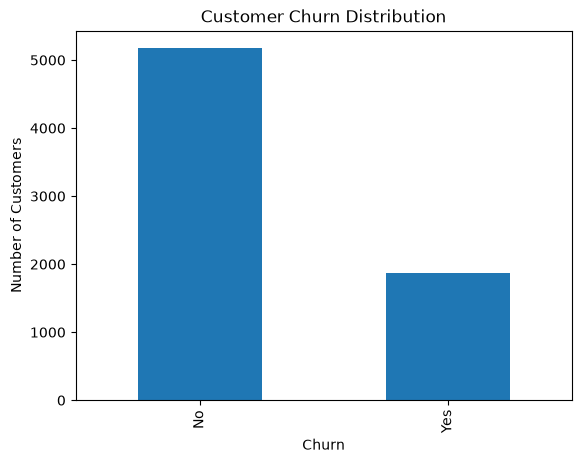

In [26]:
import matplotlib.pyplot as plt

df["Churn"].value_counts().plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

Ушли 1 869 клиентов (26,54%), остались 5 174 (73,46%). Если модель будет всем ставить `No`, Accuracy получится 73,46%, хотя ни одного уходящего клиента она не найдёт. Поэтому одной Accuracy при оценке модели будет недостаточно.

## 4. Числовые признаки

### 4.1. tenure — срок обслуживания

Проверяю, как распределён `tenure` и отличается ли он у ушедших и оставшихся клиентов.

In [27]:
df["tenure"].describe()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64

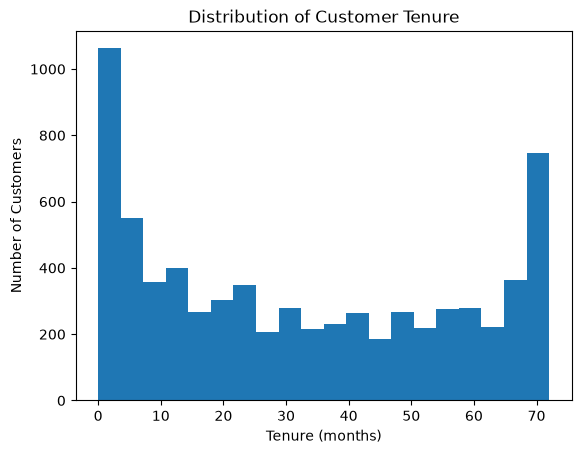

In [28]:
import matplotlib.pyplot as plt

plt.hist(df["tenure"], bins=20)
plt.title("Distribution of Customer Tenure")
plt.xlabel("Tenure (months)")
plt.ylabel("Number of Customers")
plt.show()

На гистограмме много клиентов с небольшим сроком обслуживания, но есть и скопление около 72 месяцев. Среднее — 32,37 месяца, медиана — 29. Изначально предположила, что около 30 месяцев может быть заметный перелом по оттоку; отдельно это проверю.

#### tenure по группам Churn

In [29]:
df.groupby("Churn")["tenure"].describe()

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


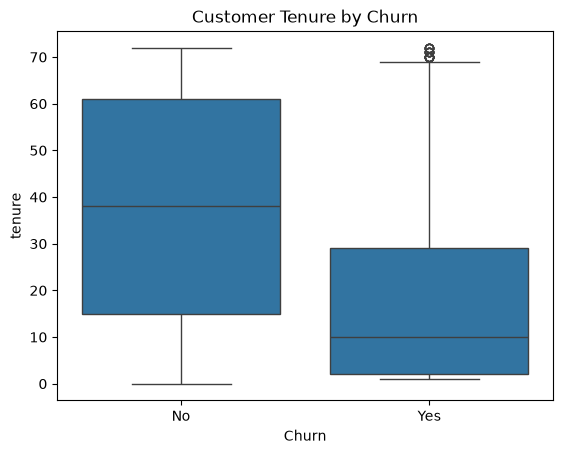

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Customer Tenure by Churn")
plt.show()

Медиана `tenure` у оставшихся — 38 месяцев, у ушедших — 10. То есть ушедшие в среднем были клиентами оператора меньше. Но по одному boxplot ещё нельзя сказать, каков процент оттока при разном `tenure`.

**Гипотеза:** после примерно 30 месяцев доля ухода может резко уменьшаться.

Разделила `tenure` на интервалы по 12 месяцев и для каждого посчитала долю `Churn = Yes`. Интервалы нужны для сравнения; границы выбраны вручную.

In [31]:
import pandas as pd

df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 36, 48, 60, 72],
    labels=["0–12", "13–24", "25–36",
            "37–48", "49–60", "61–72"]
)

In [32]:
pd.crosstab(
    df["tenure_group"],
    df["Churn"],
    normalize="index"
) * 100

Churn,No,Yes
tenure_group,,
0–12,52.561757,47.438243
13–24,71.289062,28.710938
25–36,78.365385,21.634615
37–48,80.971129,19.028871
49–60,85.576923,14.423077
61–72,93.390192,6.609808


В группе 0–12 месяцев доля оттока 47,44%, а в группе 61–72 месяца — 6,61%. Доля снижается по мере увеличения срока обслуживания. Резкого перелома около 30 месяцев в таком разбиении не видно.

**Результат:** гипотеза о границе в 30 месяцев не подтвердилась. По `tenure` видна скорее постепенная тенденция.

### 4.2. MonthlyCharges — начисления за месяц

Сначала смотрю распределение сумм, затем сравниваю начисления у ушедших и оставшихся. После этого проверю процент оттока по ценовым группам.

In [33]:
df["MonthlyCharges"].describe()

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64

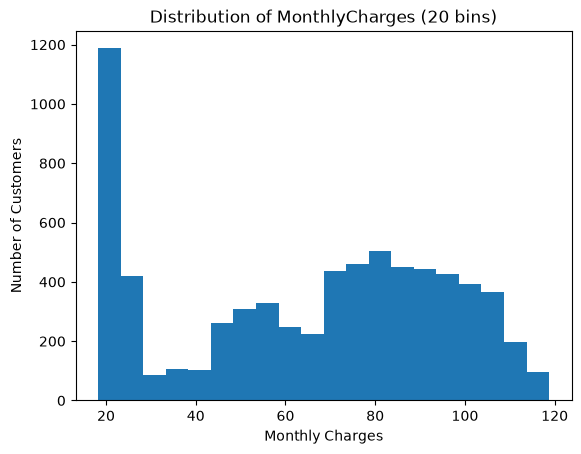

In [34]:
import matplotlib.pyplot as plt

plt.hist(df["MonthlyCharges"], bins=20)
plt.title("Distribution of MonthlyCharges (20 bins)")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.show()

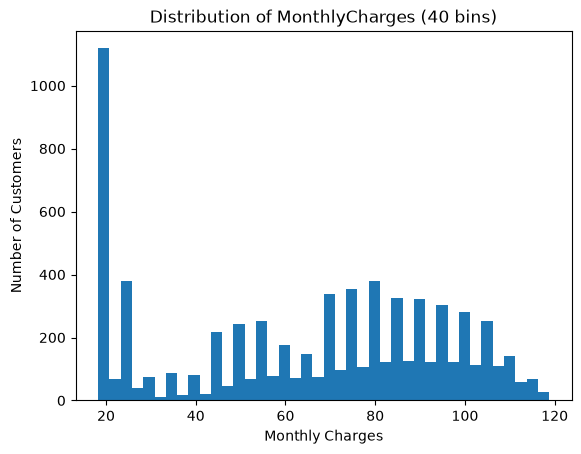

In [35]:
import matplotlib.pyplot as plt

plt.hist(df["MonthlyCharges"], bins=40)
plt.title("Distribution of MonthlyCharges (40 bins)")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.show()

Сравнила гистограммы с 20 и 40 интервалами. Есть высокий пик примерно на 18–25 и более широкое скопление в районе 70–110. Можно предположить, что это связано с разными наборами услуг, но отдельно нужно посмотреть `InternetService` и другие признаки.

#### MonthlyCharges у ушедших и оставшихся

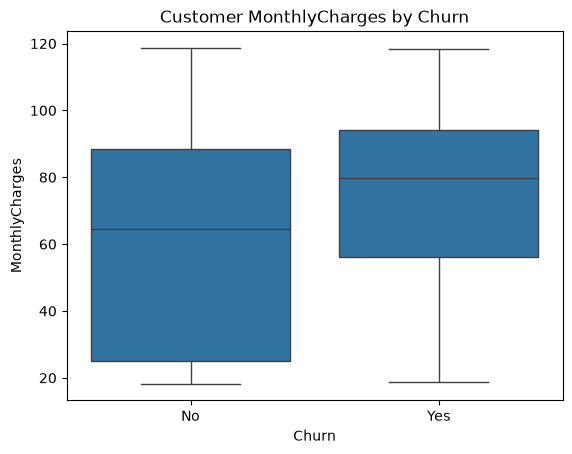

In [36]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Customer MonthlyCharges by Churn")
plt.show()

Медиана `MonthlyCharges` у ушедших — 79,65, у оставшихся — 64,43. Но здесь я сравниваю суммы внутри групп `Churn`. Чтобы понять, какая доля клиентов уходит при разной стоимости, нужно сгруппировать сами начисления.

#### Отток по ценовым диапазонам

Разбила `MonthlyCharges` на пять диапазонов. Это условные интервалы для EDA, а не реальные тарифы. После разбиения проверяю, что не потеряла строки.

In [37]:
import pandas as pd

df["MonthlyCharges_group"] = pd.cut(
    df["MonthlyCharges"],
    bins=[18, 40, 60, 80, 100, 120],
    labels=["18-40", "40-60", "60-80", "80-100", "100-120"],
    include_lowest=True
)

df["MonthlyCharges_group"].isna().sum()

np.int64(0)

In [38]:
churn_by_price = pd.crosstab(
    df["MonthlyCharges_group"],
    df["Churn"],
    normalize="index"
) * 100

churn_by_price

Churn,No,Yes
MonthlyCharges_group,,
18-40,88.356910,11.643090
40-60,74.444444,25.555556
60-80,67.580535,32.419465
80-100,62.981859,37.018141
100-120,71.951220,28.048780


Проверка разбиения: пять групп, всего 7 043 клиента, пропусков в `MonthlyCharges_group` нет.

In [39]:
churn_by_price["Yes"]

MonthlyCharges_group
18-40      11.643090
40-60      25.555556
60-80      32.419465
80-100     37.018141
100-120    28.048780
Name: Yes, dtype: float64

Для каждой ценовой группы считаю процент ушедших **от числа клиентов в этой группе**. Это важнее, чем сравнивать просто количество ушедших.

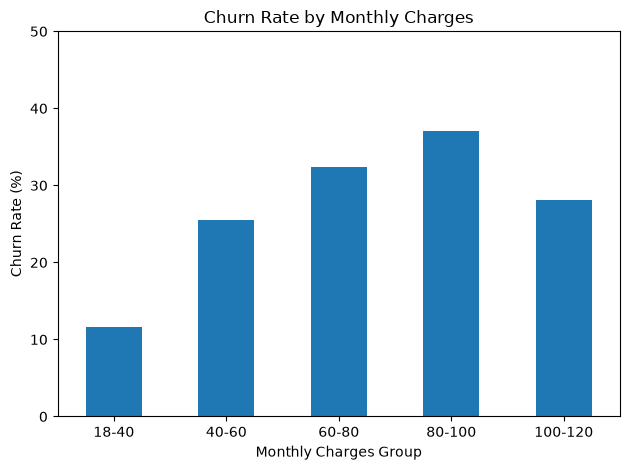

In [40]:
churn_by_price["Yes"].plot(kind="bar")
plt.title("Churn Rate by Monthly Charges")
plt.xlabel("Monthly Charges Group")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Самая высокая доля оттока получилась в диапазоне 80–100 — 37,02%. В диапазоне 100–120 она ниже — 28,05%. Значит, зависимость не выглядит как простое «чем выше начисления, тем больше отток».

### 4.3. TotalCharges — накопленные начисления

Здесь сумма зависит не только от платежа за месяц, но и от того, как давно обслуживается клиент. Поэтому после распределения отдельно посмотрю связь с `tenure`.

In [41]:
df["TotalCharges"].describe()

count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: TotalCharges, dtype: float64

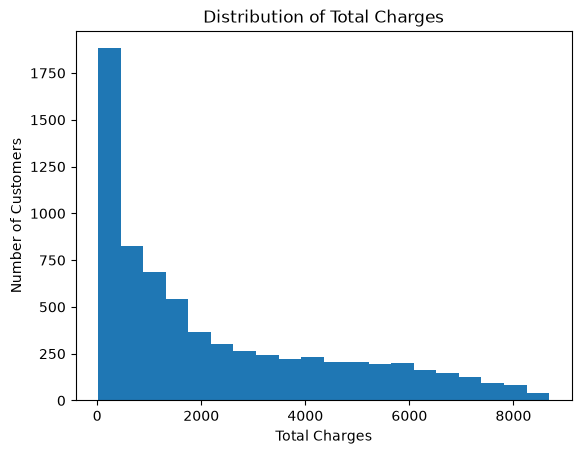

In [42]:
import matplotlib.pyplot as plt

plt.hist(df["TotalCharges"], bins=20)

plt.title("Distribution of Total Charges")
plt.xlabel("Total Charges")
plt.ylabel("Number of Customers")

plt.show()

У `TotalCharges` длинный хвост вправо: небольших накопленных сумм много, крупных — меньше. Среднее 2 283,30 выше медианы 1 397,48.

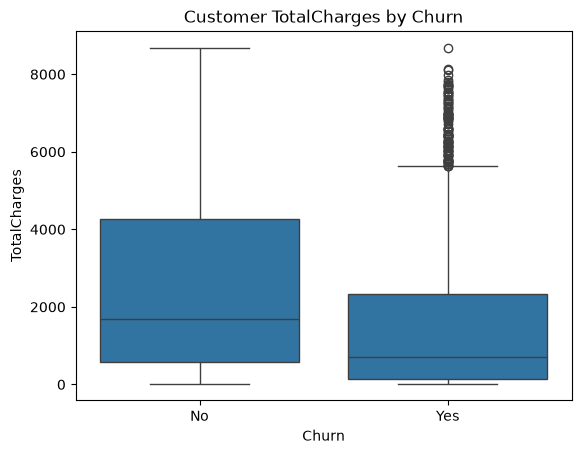

In [43]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(data=df, x="Churn", y="TotalCharges")

plt.title("Customer TotalCharges by Churn")
plt.show()

На boxplot для `Churn = Yes` есть точки выше верхнего уса. По правилу IQR это выбросы, но не обязательно ошибки: клиент мог долго обслуживаться и много платить каждый месяц.

In [44]:
df.loc[
    (df["Churn"] == "Yes") & (df["TotalCharges"] > 5600),
    ["tenure", "MonthlyCharges", "TotalCharges"]
]

,tenure,MonthlyCharges,TotalCharges
104,68,110.00,7611.85
276,52,105.05,5624.85
339,63,103.40,6603.00
402,69,99.45,7007.60
445,60,105.90,6396.45
...,...,...,...
6819,55,98.80,5617.75
6853,54,111.10,6014.85
6945,70,98.30,6859.50
6972,56,111.95,6418.90


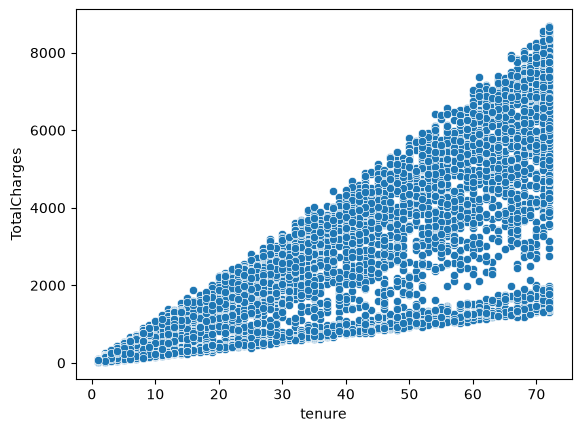

In [45]:
sns.scatterplot(
    data=df,
    x="tenure",
    y="TotalCharges"
)
plt.show()

In [46]:
df[["tenure", "TotalCharges"]].corr()

,tenure,TotalCharges
tenure,1.00000,0.82588
TotalCharges,0.82588,1.00000


Корреляция Пирсона между `tenure` и `TotalCharges` — около 0,826. Большие суммы часто встречаются у клиентов с долгим сроком обслуживания. Медиана `TotalCharges` у оставшихся выше (1 683,60 против 703,55 у ушедших), но здесь нужно учитывать разницу по `tenure`. Оба признака пока оставляю: их пользу для модели лучше проверить отдельно.

## 5. Договор, интернет и способ оплаты

Для категориальных признаков сравниваю долю `Churn = Yes` внутри каждой категории, а не число ушедших. Размеры групп могут сильно отличаться.

### 5.1. Contract

In [47]:
df["Contract"].value_counts()

Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64

In [48]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


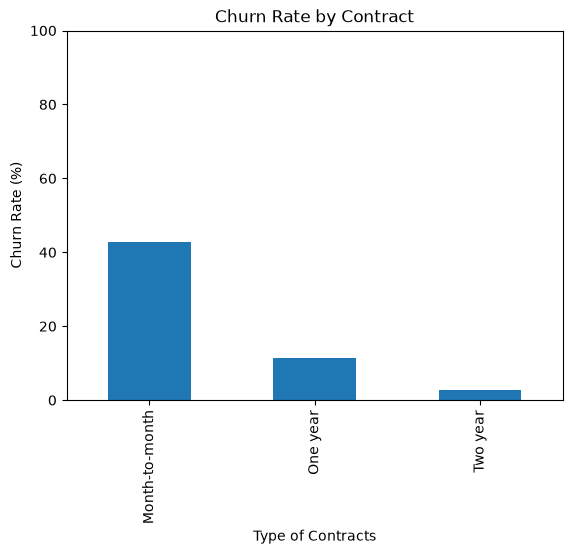

In [49]:
contract_churn["Yes"].plot(kind="bar")
plt.title("Churn Rate by Contract")
plt.xlabel("Type of Contracts")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.show()

По помесячным договорам ушли 42,71% клиентов, по годовым — 11,27%, по двухлетним — 2,83%. `Contract` явно стоит проверить в модели. Ещё важно сравнить его с `tenure`: тип договора и срок обслуживания могут быть связаны.

### 5.2. InternetService

In [50]:
df["InternetService"].describe()

count            7043
unique              3
top       Fiber optic
freq             3096
Name: InternetService, dtype: object

In [51]:
df["InternetService"].value_counts()

InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

In [52]:
internet_churn = pd.crosstab(
    df["InternetService"],
    df["Churn"],
    normalize="index"
) * 100

internet_churn

Churn,No,Yes
InternetService,,
DSL,81.040892,18.959108
Fiber optic,58.107235,41.892765
No,92.595020,7.404980


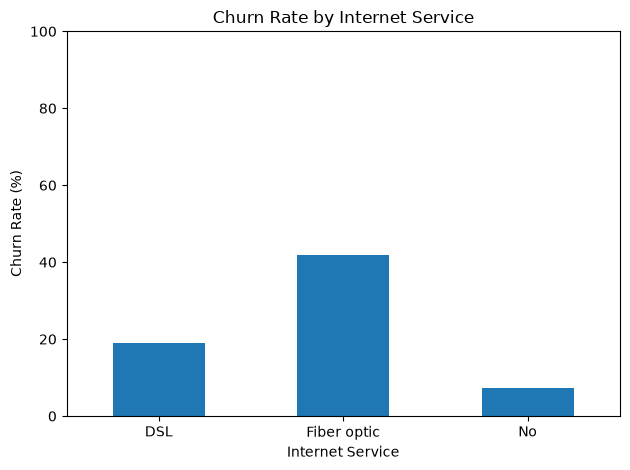

In [53]:
internet_churn["Yes"].plot(kind="bar")
plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Доля оттока у `Fiber optic` — 41,89%, у `DSL` — 18,96%, без интернета — 7,40%. Разница между Fiber optic и DSL составляет около 22,93 процентного пункта. Проверю, не отличается ли у этих групп ежемесячная стоимость.

In [54]:
df.groupby("InternetService")["MonthlyCharges"].describe()

,count,mean,std,min,25%,50%,75%,max
InternetService,,,,,,,,
DSL,2421.0,58.102169,16.259522,23.45,46.20,56.150,69.90,94.80
Fiber optic,3096.0,91.500129,12.663039,67.75,80.55,91.675,101.15,118.75
No,1526.0,21.079194,2.164221,18.25,19.70,20.150,20.90,26.90


Медиана `MonthlyCharges` у `Fiber optic` — 91,68, у `DSL` — 56,15. Высокий отток и высокая стоимость встречаются в одной группе. Теперь интересно, что будет при сравнении клиентов с похожими договорами и сроками обслуживания.

### 5.3. PaymentMethod

Сравниваю доли оттока по способам оплаты, затем проверяю договоры, срок обслуживания и начисления в этих группах.

In [55]:
df["PaymentMethod"].value_counts()

PaymentMethod
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: count, dtype: int64

In [56]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"],
    normalize="index"
) * 100

payment_churn

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.290155,16.709845
Credit card (automatic),84.756899,15.243101
Electronic check,54.714588,45.285412
Mailed check,80.893300,19.106700


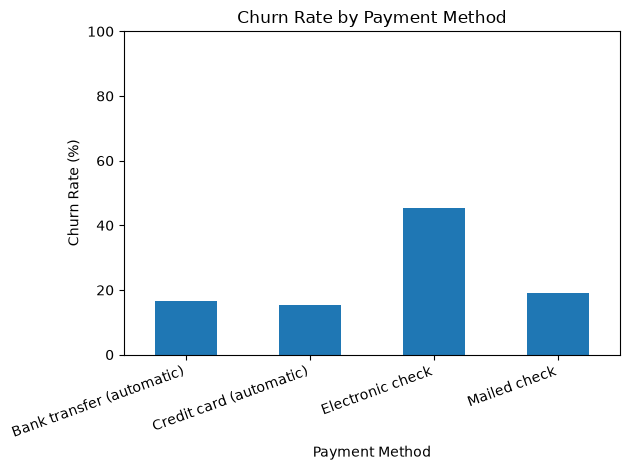

In [57]:
payment_churn["Yes"].plot(kind="bar")
plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

У `Electronic check` доля оттока 45,29%. Для сравнения: автоматическая оплата картой — 15,24%, банковским переводом — 16,71%, `Mailed check` — 19,11%. Разница заметная; дальше проверю, не связана ли она с распределением договоров.

### 5.4. PaymentMethod вместе с Contract и tenure

`Electronic check` и `Month-to-month` по отдельности выделяются по доле оттока. Сравню способы оплаты внутри одного типа договора и посмотрю сроки обслуживания.

In [58]:
pd.crosstab(
    df["PaymentMethod"],
    df["Contract"],
    normalize="index"
) * 100

Contract,Month-to-month,One year,Two year
PaymentMethod,,,
Bank transfer (automatic),38.147668,25.323834,36.528497
Credit card (automatic),35.676741,26.149803,38.173456
Electronic check,78.224101,14.672304,7.103594
Mailed check,55.397022,20.905707,23.697270


In [59]:
df.groupby("PaymentMethod")["tenure"].median()

PaymentMethod
Bank transfer (automatic)    48.0
Credit card (automatic)      47.0
Electronic check             18.0
Mailed check                 15.0
Name: tenure, dtype: float64

In [60]:
df.groupby("PaymentMethod")["MonthlyCharges"].median()

PaymentMethod
Bank transfer (automatic)    73.100
Credit card (automatic)      73.025
Electronic check             80.550
Mailed check                 34.700
Name: MonthlyCharges, dtype: float64

Среди клиентов с `Electronic check` 78,2% используют помесячные договоры, медиана `tenure` — 18 месяцев. У `Mailed check` срок ещё меньше (15 месяцев), но медиана `MonthlyCharges` намного ниже: 34,70 против 80,55. Одного `tenure` для объяснения различий между оплатами явно недостаточно.

In [61]:
pd.crosstab(
    [df["Contract"], df["PaymentMethod"]],
    df["Churn"],
    normalize="index"
) * 100

Churn                                            No        Yes
Contract       PaymentMethod                                  
Month-to-month Bank transfer (automatic)  65.874363  34.125637
               Credit card (automatic)    67.219153  32.780847
               Electronic check           46.270270  53.729730
               Mailed check               68.421053  31.578947
One year       Bank transfer (automatic)  90.281330   9.718670
               Credit card (automatic)    89.698492  10.301508
               Electronic check           81.556196  18.443804
               Mailed check               93.175074   6.824926
Two year       Bank transfer (automatic)  96.631206   3.368794
               Credit card (automatic)    97.762478   2.237522
               Electronic check           92.261905   7.738095
               Mailed check               99.214660   0.785340

In [62]:
pd.crosstab(
    [df["Contract"], df["PaymentMethod"]],
    df["Churn"],
) 

Churn                                      No  Yes
Contract       PaymentMethod                      
Month-to-month Bank transfer (automatic)  388  201
               Credit card (automatic)    365  178
               Electronic check           856  994
               Mailed check               611  282
One year       Bank transfer (automatic)  353   38
               Credit card (automatic)    357   41
               Electronic check           283   64
               Mailed check               314   23
Two year       Bank transfer (automatic)  545   19
               Credit card (automatic)    568   13
               Electronic check           155   13
               Mailed check               379    3

Максимальная доля ухода у сочетания `Month-to-month + Electronic check` — 53,73% (1 850 клиентов в этой группе). При сравнении внутри каждого типа договора `Electronic check` тоже показывает более высокую долю оттока. То есть тип договора не объясняет всю разницу. Причину ухода по этим данным определить нельзя.

## 6. Дополнительные услуги

Проверяю интернет-услуги отдельно. Здесь `No internet service` означает отсутствие интернета, а не отказ от конкретной допуслуги.

### 6.1. TechSupport

In [63]:
df["TechSupport"].value_counts()

TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

In [64]:
support_churn = pd.crosstab(
    df["TechSupport"],
    df["Churn"],
    normalize="index"
) * 100

support_churn 

Churn,No,Yes
TechSupport,,
No,58.364526,41.635474
No internet service,92.595020,7.404980
Yes,84.833659,15.166341


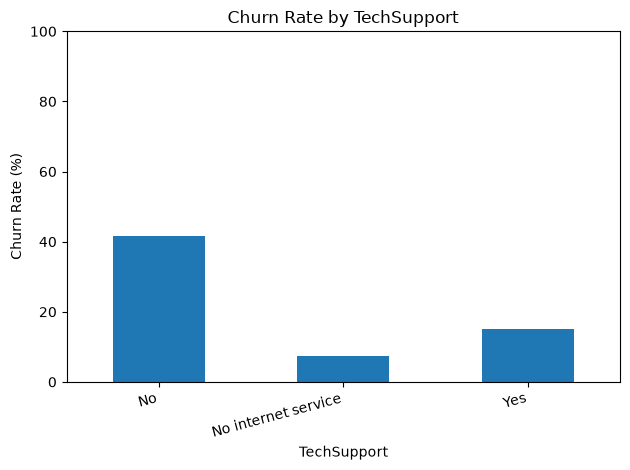

In [65]:
support_churn["Yes"].plot(kind="bar")
plt.title("Churn Rate by TechSupport")
plt.xlabel("TechSupport")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

Для `TechSupport = No` доля оттока 41,64%, для `Yes` — 15,17%. У категории `No internet service` — 7,40%. Последнюю в группу `No` не добавляю: это клиенты без интернета.

### 6.2. OnlineSecurity

In [66]:
df["OnlineSecurity"].value_counts()

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

In [67]:
security_churn = pd.crosstab(
    df["OnlineSecurity"],
    df["Churn"],
    normalize="index"
) * 100

security_churn

Churn,No,Yes
OnlineSecurity,,
No,58.233276,41.766724
No internet service,92.595020,7.404980
Yes,85.388806,14.611194


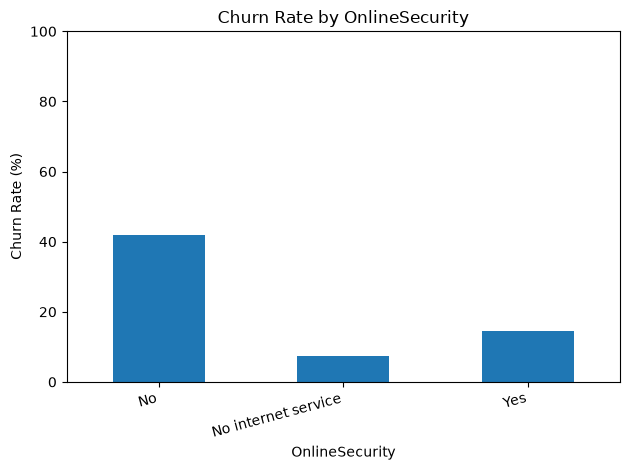

In [68]:
security_churn["Yes"].plot(kind="bar")
plt.title("Churn Rate by OnlineSecurity")
plt.xlabel("OnlineSecurity")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

Для `OnlineSecurity = No` доля оттока 41,77%, для `Yes` — 14,61%. График строю по отдельной таблице `security_churn`, чтобы не продублировать результаты `TechSupport`.

### 6.3. OnlineBackup

In [69]:
df["OnlineBackup"].value_counts()

OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

In [70]:
backup_churn = pd.crosstab(
    df["OnlineBackup"],
    df["Churn"],
    normalize="index"
) * 100

backup_churn

Churn,No,Yes
OnlineBackup,,
No,60.071244,39.928756
No internet service,92.595020,7.404980
Yes,78.468506,21.531494


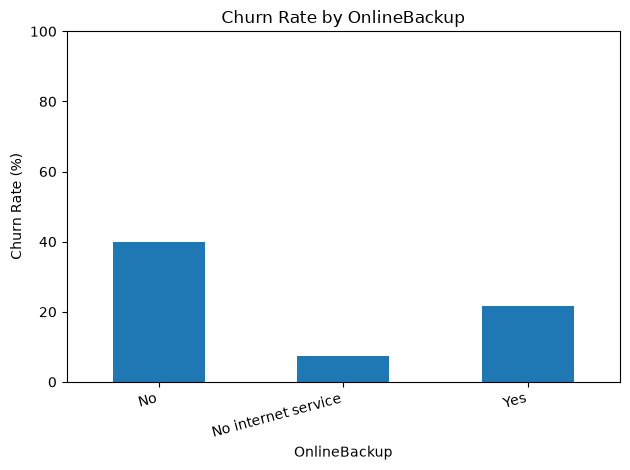

In [71]:
backup_churn["Yes"].plot(kind="bar")
plt.title("Churn Rate by OnlineBackup")
plt.xlabel("OnlineBackup")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

Для `OnlineBackup` разница меньше: `No` — 39,93%, `Yes` — 21,53%. Здесь также нужна своя таблица (`backup_churn`), иначе можно случайно получить график другой услуги.

### 6.4. DeviceProtection

In [72]:
df["DeviceProtection"].value_counts()

DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64

In [73]:
protection_churn = pd.crosstab(
    df["DeviceProtection"],
    df["Churn"],
    normalize="index"
) * 100

protection_churn

Churn,No,Yes
DeviceProtection,,
No,60.872375,39.127625
No internet service,92.595020,7.404980
Yes,77.497936,22.502064


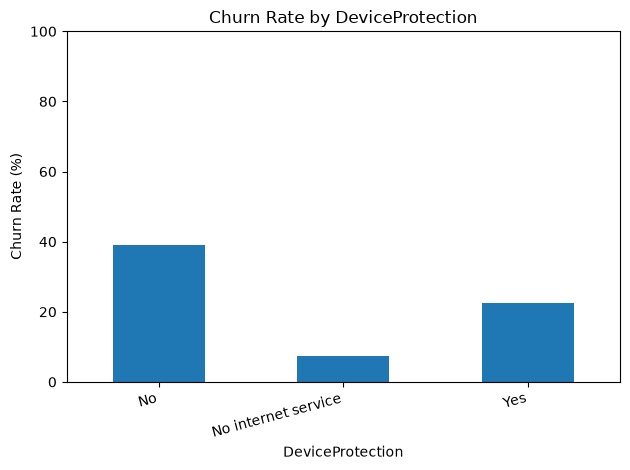

In [74]:
protection_churn["Yes"].plot(kind="bar")
plt.title("Churn Rate by DeviceProtection")
plt.xlabel("DeviceProtection")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

У `DeviceProtection = No` отток 39,13%, у `Yes` — 22,50%. Проверю эти услуги вместе с `Contract` и `tenure`, потому что состав групп может различаться.

### 6.5. StreamingTV, StreamingMovies, MultipleLines

Эти признаки проверяю одним циклом: для каждого заново рассчитываю долю оттока и строю отдельный график.

In [75]:
features = [
    "DeviceProtection",
    "StreamingTV",
    "StreamingMovies",
    "MultipleLines"
]

for feature in features:
    print(feature)
    print(df[feature].value_counts())

DeviceProtection
DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64
StreamingTV
StreamingTV
No                     2810
Yes                    2707
No internet service    1526
Name: count, dtype: int64
StreamingMovies
StreamingMovies
No                     2785
Yes                    2732
No internet service    1526
Name: count, dtype: int64
MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64


DeviceProtection: доля Churn=Yes по категориям
DeviceProtection
No                     39.13
No internet service     7.40
Yes                    22.50
Name: Yes, dtype: float64


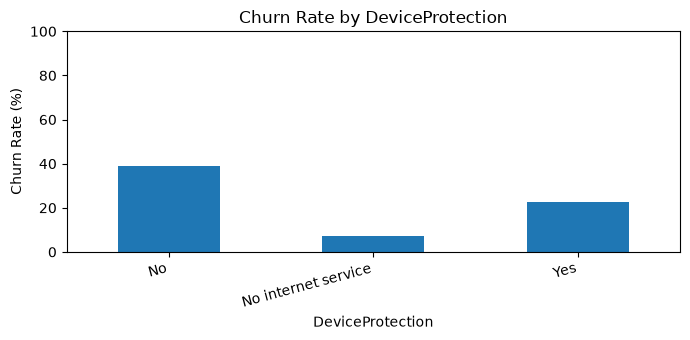

StreamingTV: доля Churn=Yes по категориям
StreamingTV
No                     33.52
No internet service     7.40
Yes                    30.07
Name: Yes, dtype: float64


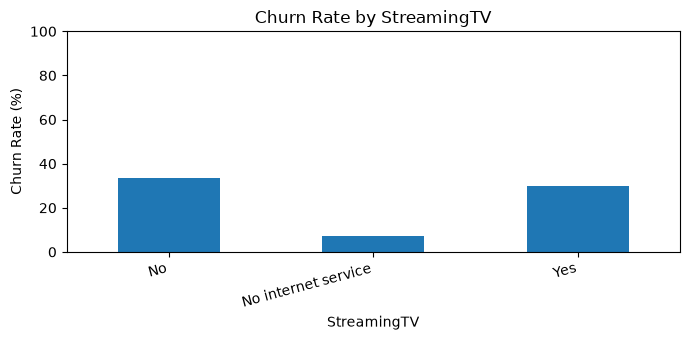

StreamingMovies: доля Churn=Yes по категориям
StreamingMovies
No                     33.68
No internet service     7.40
Yes                    29.94
Name: Yes, dtype: float64


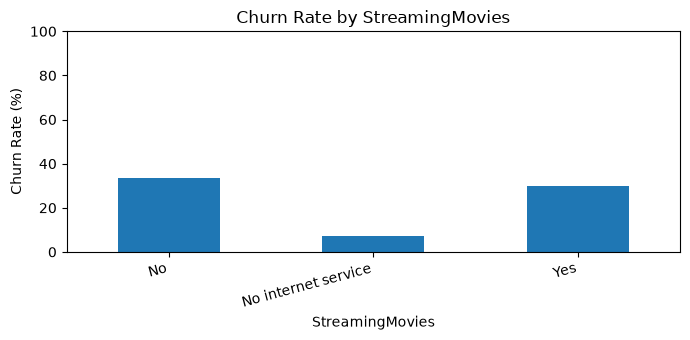

MultipleLines: доля Churn=Yes по категориям
MultipleLines
No                  25.04
No phone service    24.93
Yes                 28.61
Name: Yes, dtype: float64


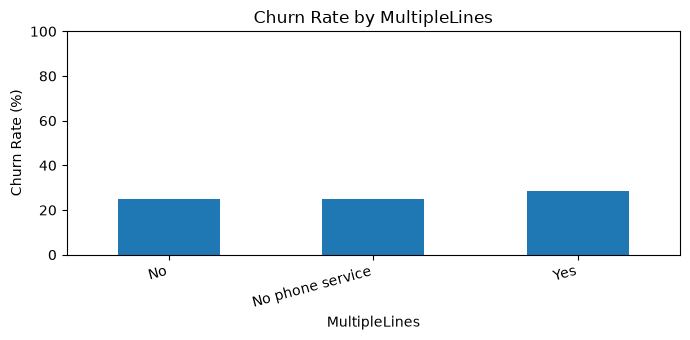

In [76]:
features = [
    "DeviceProtection",
    "StreamingTV",
    "StreamingMovies",
    "MultipleLines"
]

for feature in features:
    churn_table = pd.crosstab(
        df[feature],
        df["Churn"],
        normalize="index"
    ) * 100

    print(f"{feature}: доля Churn=Yes по категориям")
    print(churn_table["Yes"].round(2))

    churn_table["Yes"].plot(kind="bar", figsize=(7, 3.5))
    plt.title(f"Churn Rate by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Churn Rate (%)")
    plt.ylim(0, 100)
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.show()

У `StreamingTV` и `StreamingMovies` различие между `Yes` и `No` меньше, чем у поддержки и безопасности. У `MultipleLines` тоже нет такого большого разрыва. Поэтому по дополнительным услугам лучше делать отдельные выводы, а не объединять их в одну категорию.

### 6.6. Что означает No internet service

`No` — интернет есть, но допуслуга не подключена. `No internet service` — самого интернета нет. Проверяю это через `InternetService`, затем отдельно сравниваю клиентов с интернетом.

In [77]:
pd.crosstab(df["InternetService"], df["TechSupport"])

TechSupport,No,No internet service,Yes
InternetService,,,
DSL,1243,0,1178
Fiber optic,2230,0,866
No,0,1526,0


In [78]:
internet_clients = df[df["InternetService"] != "No"]
for feature in ["TechSupport", "OnlineSecurity", "OnlineBackup", "DeviceProtection"]:
    compare = pd.crosstab(internet_clients[feature], internet_clients["Churn"], normalize="index") * 100
    print(f"{feature}: доля оттока среди интернет-клиентов, %")
    print(compare["Yes"].round(2), "\n")

TechSupport: доля оттока среди интернет-клиентов, %
TechSupport
No     41.64
Yes    15.17
Name: Yes, dtype: float64 

OnlineSecurity: доля оттока среди интернет-клиентов, %
OnlineSecurity
No     41.77
Yes    14.61
Name: Yes, dtype: float64 

OnlineBackup: доля оттока среди интернет-клиентов, %
OnlineBackup
No     39.93
Yes    21.53
Name: Yes, dtype: float64 

DeviceProtection: доля оттока среди интернет-клиентов, %
DeviceProtection
No     39.13
Yes    22.50
Name: Yes, dtype: float64 



Проверка подтвердила, что `No internet service` относится к клиентам без интернета. Объединять эту категорию с `No` в текущем анализе не стала.

## 7. Остальные категориальные признаки

Остались характеристики клиентов, формат счетов и телефонные услуги. Проверю их тем же способом — доля оттока внутри каждой категории.

### 7.1. gender, SeniorCitizen, Partner, Dependents

`SeniorCitizen` записан как 0/1, но по смыслу это категориальный признак. Сначала считаю размер групп, потом процент ушедших.

In [79]:
profile_features = ["gender", "SeniorCitizen", "Partner", "Dependents"]

for feature in profile_features:
    counts = pd.crosstab(df[feature], df["Churn"])
    counts["Total"] = counts.sum(axis=1)
    counts["Churn rate (%)"] = (counts["Yes"] / counts["Total"] * 100).round(2)
    print(f"\n{feature}")
    print(counts)


gender
Churn     No  Yes  Total  Churn rate (%)
gender                                  
Female  2549  939   3488           26.92
Male    2625  930   3555           26.16

SeniorCitizen
Churn            No   Yes  Total  Churn rate (%)
SeniorCitizen                                   
0              4508  1393   5901           23.61
1               666   476   1142           41.68

Partner
Churn      No   Yes  Total  Churn rate (%)
Partner                                   
No       2441  1200   3641           32.96
Yes      2733   669   3402           19.66

Dependents
Churn         No   Yes  Total  Churn rate (%)
Dependents                                   
No          3390  1543   4933           31.28
Yes         1784   326   2110           15.45


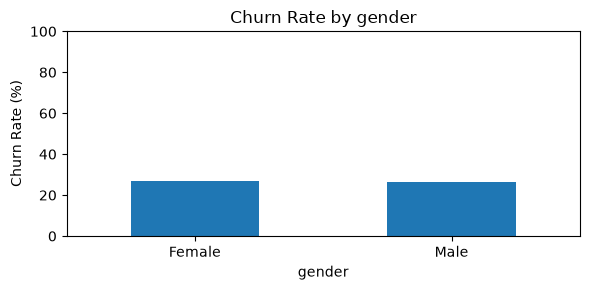

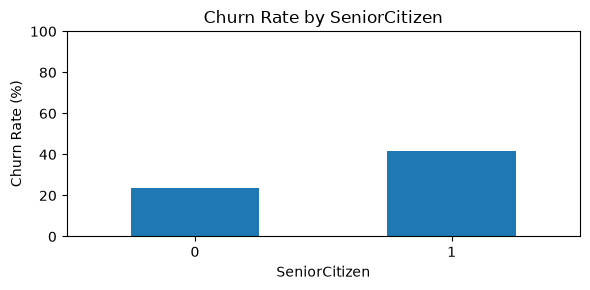

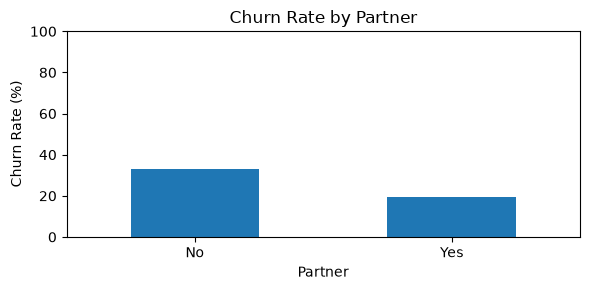

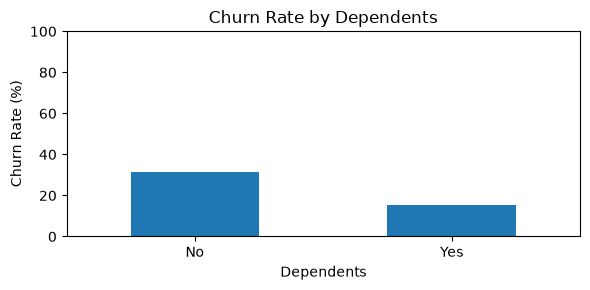

In [80]:
for feature in profile_features:
    rates = pd.crosstab(df[feature], df["Churn"], normalize="index") * 100
    rates["Yes"].plot(kind="bar", figsize=(6, 3))
    plt.title(f"Churn Rate by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Churn Rate (%)")
    plt.ylim(0, 100)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

У `SeniorCitizen = 1` доля оттока 41,68% против 23,61% у остальных. Без `Partner` — 32,96% против 19,66%, без `Dependents` — 31,28% против 15,45%. По `gender` разница небольшая: 26,92% и 26,16%. Эти признаки оставляю как кандидатов для модели; отдельно надо проверить их вместе с другими характеристиками.

### 7.2. PaperlessBilling, PhoneService, MultipleLines

`PaperlessBilling` — электронные счета, не способ оплаты. `No phone service` в `MultipleLines` означает отсутствие телефонной услуги. Оставляю это значение отдельно.

In [81]:
billing_phone_features = ["PaperlessBilling", "PhoneService", "MultipleLines"]

for feature in billing_phone_features:
    counts = pd.crosstab(df[feature], df["Churn"])
    counts["Total"] = counts.sum(axis=1)
    counts["Churn rate (%)"] = (counts["Yes"] / counts["Total"] * 100).round(2)
    print(f"\n{feature}")
    print(counts)


PaperlessBilling
Churn               No   Yes  Total  Churn rate (%)
PaperlessBilling                                   
No                2403   469   2872           16.33
Yes               2771  1400   4171           33.57

PhoneService
Churn           No   Yes  Total  Churn rate (%)
PhoneService                                   
No             512   170    682           24.93
Yes           4662  1699   6361           26.71

MultipleLines
Churn               No  Yes  Total  Churn rate (%)
MultipleLines                                     
No                2541  849   3390           25.04
No phone service   512  170    682           24.93
Yes               2121  850   2971           28.61


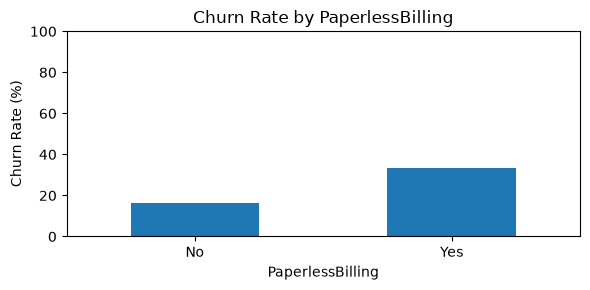

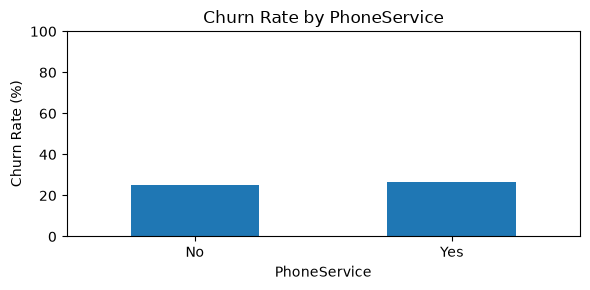

In [82]:
for feature in billing_phone_features[:2]:
    rates = pd.crosstab(df[feature], df["Churn"], normalize="index") * 100
    rates["Yes"].plot(kind="bar", figsize=(6, 3))
    plt.title(f"Churn Rate by {feature}")
    plt.xlabel(feature)
    plt.ylabel("Churn Rate (%)")
    plt.ylim(0, 100)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [83]:
pd.crosstab(df["PhoneService"], df["MultipleLines"])

MultipleLines,No,No phone service,Yes
PhoneService,,,
No,0,682,0
Yes,3390,0,2971


При `PaperlessBilling = Yes` отток 33,57%, при `No` — 16,33%. По `PhoneService` разница небольшая — 26,71% и 24,93%. Для `MultipleLines` отличие также меньше, чем для `Contract` или `InternetService`.

## 8. Связи между признаками

Часть различий по оттоку может объясняться тем, что сами признаки связаны друг с другом. Например, тип договора — со сроком обслуживания, а интернет — со стоимостью.

### 8.1. Корреляции числовых признаков

Считаю Pearson для линейных связей и Spearman для монотонных. Сравниваю `tenure`, `MonthlyCharges` и `TotalCharges`.

In [84]:
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]

print("Pearson")
print(df[numeric_features].corr(method="pearson").round(3))
print("\nSpearman")
print(df[numeric_features].corr(method="spearman").round(3))

Pearson
                tenure  MonthlyCharges  TotalCharges
tenure           1.000           0.248         0.826
MonthlyCharges   0.248           1.000         0.651
TotalCharges     0.826           0.651         1.000

Spearman
                tenure  MonthlyCharges  TotalCharges
tenure           1.000           0.276         0.889
MonthlyCharges   0.276           1.000         0.638
TotalCharges     0.889           0.638         1.000


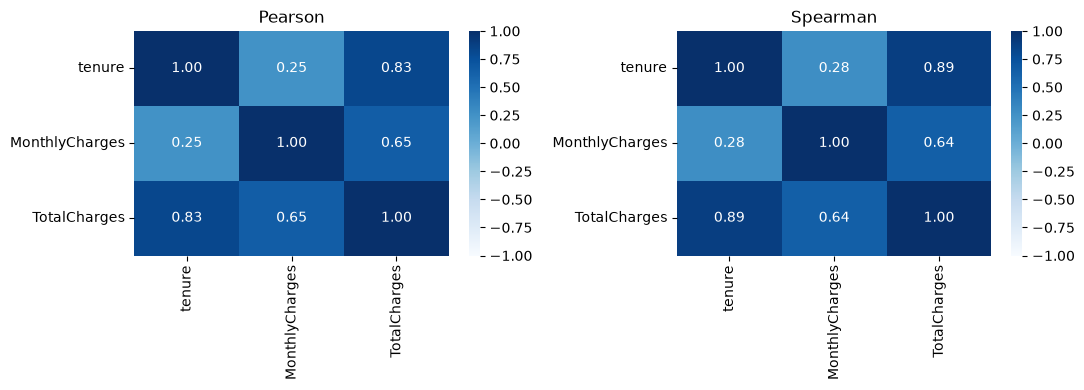

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(df[numeric_features].corr(method="pearson"), annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Pearson")
sns.heatmap(df[numeric_features].corr(method="spearman"), annot=True, fmt=".2f", cmap="Blues", vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Spearman")
plt.tight_layout()
plt.show()

`TotalCharges` связан с `tenure` (Pearson ≈ 0,826) и с `MonthlyCharges` (≈ 0,651). Для накопленных начислений это ожидаемо. В линейной модели стоит отдельно проверить, как коррелирующие признаки влияют на коэффициенты. Удалять их только из-за корреляции пока не стала.

### 8.2. Корреляции смешанных признаков — φk

Pearson не подходит для пары категорий вроде `Contract` и `Churn`. Поэтому добавила φk для числовых и категориальных признаков. Значение показывает силу связи, но не её направление.

,Churn,Contract,PaymentMethod,InternetService,TechSupport,OnlineSecurity,tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Partner,Dependents
Churn,1.00,0.25,0.45,0.20,0.21,0.21,0.47,0.36,0.28,0.23,0.23,0.25
Contract,0.25,1.00,0.28,0.51,0.67,0.64,0.66,0.39,0.51,0.09,0.18,0.15
PaymentMethod,0.45,0.28,1.00,0.32,0.32,0.32,0.38,0.40,0.35,0.29,0.24,0.22
InternetService,0.20,0.51,0.32,1.00,0.95,0.95,0.02,0.92,0.51,0.16,0.00,0.11
TechSupport,0.21,0.67,0.32,0.95,1.00,0.95,0.36,0.82,0.54,0.14,0.08,0.11
OnlineSecurity,0.21,0.64,0.32,0.95,0.95,1.00,0.37,0.81,0.53,0.13,0.09,0.12
tenure,0.47,0.66,0.38,0.02,0.36,0.37,1.00,0.41,0.84,0.03,0.49,0.21
MonthlyCharges,0.36,0.39,0.40,0.92,0.82,0.81,0.41,1.00,0.76,0.30,0.20,0.18
TotalCharges,0.28,0.51,0.35,0.51,0.54,0.53,0.84,0.76,1.00,0.15,0.42,0.12
SeniorCitizen,0.23,0.09,0.29,0.16,0.14,0.13,0.03,0.30,0.15,1.00,0.02,0.32


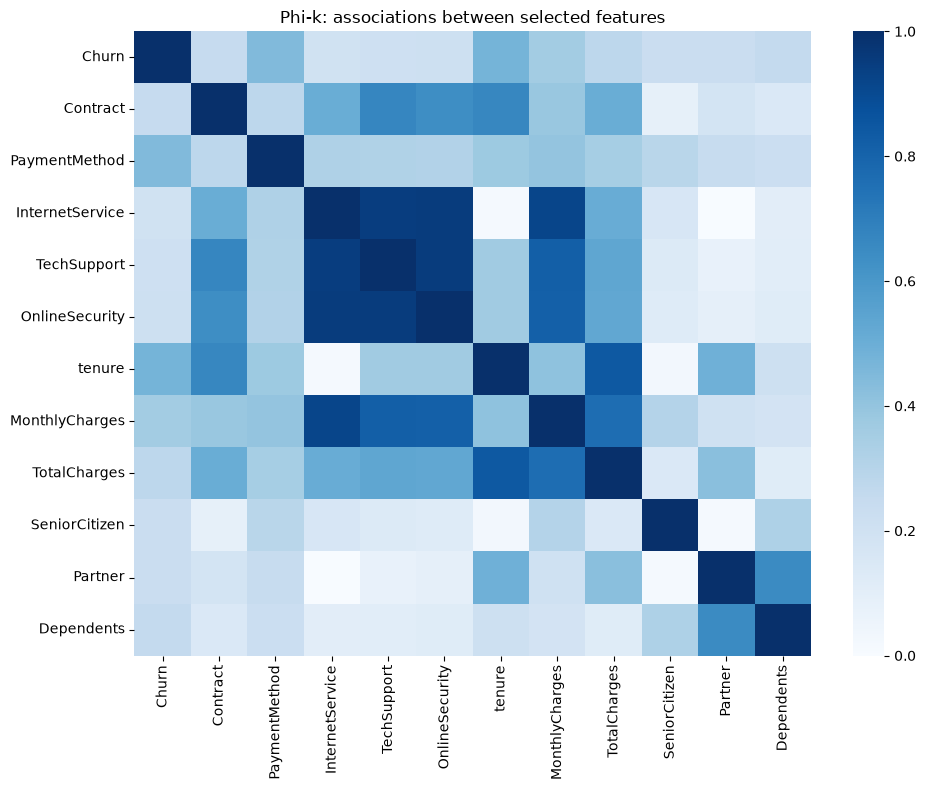

In [89]:
phi_columns = [
    "Churn", "Contract", "PaymentMethod", "InternetService",
    "TechSupport", "OnlineSecurity", "tenure", "MonthlyCharges",
    "TotalCharges", "SeniorCitizen", "Partner", "Dependents"
]

try:
    import phik  # добавляет метод phik_matrix() к DataFrame

    phi_data = df[phi_columns].copy()
    phi_data["SeniorCitizen"] = phi_data["SeniorCitizen"].map({0: "No", 1: "Yes"})
    phi_matrix = phi_data.phik_matrix(
        interval_cols=["tenure", "MonthlyCharges", "TotalCharges"]
    )

    display(phi_matrix.round(2))
    plt.figure(figsize=(10, 8))
    sns.heatmap(phi_matrix, cmap="Blues", vmin=0, vmax=1)
    plt.title("Phi-k: associations between selected features")
    plt.tight_layout()
    plt.show()
except ImportError:
    print("Не установлена phik. В папке проекта выполни uv sync и перезапусти ядро ноутбука.")

По φk самая заметная связь с `Churn` у `tenure` (0,47), `PaymentMethod` (0,45) и `MonthlyCharges` (0,36). У `Contract` коэффициент 0,25, хотя при сравнении отдельных типов договоров разница в оттоке довольно большая. Поэтому одной матрицы недостаточно, нужно учитывать и результаты предыдущих проверок.

Между самими признаками связи местами намного сильнее. Например, `InternetService` связан с `TechSupport` и `OnlineSecurity` (по 0,95), а также с `MonthlyCharges` (0,92). В первых двух случаях это ожидаемо, поскольку у клиентов без интернета в дополнительных услугах стоит отдельная категория `No internet service`.

У `tenure` и `TotalCharges` коэффициент 0,84, что подтверждает предыдущий анализ: общая сумма начислений сильно связана со сроком обслуживания. Также заметна связь `Contract` с `tenure` (0,66).

Для модели стоит проверить, насколько полезно оставлять все эти признаки одновременно. Пока удалять ничего не буду: высокий φk сам по себе не означает, что один из признаков лишний.

### 8.3. Contract и tenure

Сравниваю медианный `tenure` по договорам и долю оттока при сочетаниях `Contract` × `tenure_group`. Для небольших групп важно смотреть не только процент, но и количество клиентов.

In [87]:
df.groupby("Contract")["tenure"].median()

Contract
Month-to-month    12.0
One year          44.0
Two year          64.0
Name: tenure, dtype: float64

In [88]:
contract_tenure = (
    df.groupby(["Contract", "tenure_group"], observed=True)["Churn"]
      .agg(clients="size", churned=lambda s: (s == "Yes").sum())
)
contract_tenure["churn_rate_pct"] = (
    contract_tenure["churned"] / contract_tenure["clients"] * 100
).round(2)
contract_tenure

clients  churned  churn_rate_pct
Contract       tenure_group                                  
Month-to-month 0–12             1994     1024           51.35
               13–24             737      278           37.72
               25–36             486      158           32.51
               37–48             316      106           33.54
               49–60             234       65           27.78
               61–72             108       24           22.22
One year       0–12              124       13           10.48
               13–24             197       16            8.12
               25–36             250       20            8.00
               37–48             268       35           13.06
               49–60             321       44           13.71
               61–72             313       38           12.14
Two year       0–12               68        0            0.00
               13–24              90        0            0.00
               25–36              96        2            2.08
               37–48             178        4            2.25
               49–60             277       11            3.97
               61–72             986       31            3.14

Здесь проверяю, сохраняется ли разница по типу договора среди клиентов с близким сроком обслуживания. Если в сочетании мало клиентов, по одному проценту вывод делать рано.

## 9. Итоги 

Ниже собрала основные результаты и то, что стоит проверить на этапе подготовки данных и первой модели.

| Признак | Что получилось | Что проверить дальше |
|---|---|---|
| `Contract` | 42,71% оттока с `Month-to-month`, 2,83% с `Two year` | Сравнить вместе с `tenure` |
| `tenure` | 47,44% оттока в группе 0–12 месяцев и 6,61% в группе 61–72 | Проверить форму связи, сочетание с договором |
| `InternetService` | `Fiber optic` — 41,89%, `DSL` — 18,96% | Сравнить с `MonthlyCharges`, `Contract`, `tenure` |
| `PaymentMethod` | `Electronic check` — 45,29%; в сочетании с `Month-to-month` — 53,73% | Проверить оплату и договор одновременно |
| `MonthlyCharges` | Самая высокая доля оттока в диапазоне 80–100 (37,02%) | Не считать связь строго возрастающей |
| Интернет-услуги | `TechSupport = No` — 41,64%; `OnlineSecurity = No` — 41,77% | Сравнить с договором и сроком обслуживания |
| `TotalCharges` | Pearson с `tenure` ≈ 0,826; есть длинный правый хвост | Проверить полезность обоих признаков |
| Профиль и счета | Разница по `SeniorCitizen`, `Partner`, `Dependents`, `PaperlessBilling`; небольшая — по `gender` | Проверить в модели вместе с остальными признаками |

### 9.1. Что оставила как есть и что нужно решить позже

- **Дубликаты:** нет ни полных повторов, ни повторных `customerID`.
- **Пропуски:** 11 значений `TotalCharges` отсутствуют при `tenure = 0`. Пока оставляю `NaN`. Заполнение или удаление — уже на этапе подготовки данных.
- **Категории:** `No internet service` и `No phone service` — отдельные значения, а не технические пропуски.
- **Большие TotalCharges:** автоматически не удаляю, часть объясняется длительным обслуживанием и высокими начислениями.
- **Подготовка модели:** `customerID` не использовать как признак. Обработку пропусков, кодирование и масштабирование настраивать только по train-части.
- **Оценка модели:** из-за соотношения `Churn` 73,46% / 26,54% смотреть не только Accuracy, но и Recall, Precision, F1, ROC-AUC. Основную метрику выбрать под бизнес-задачу.

### 9.2. Что ограничивает выводы

В датасете нет истории изменения тарифов, причин отключения и деталей отдельных платежей. По этим данным можно сравнить группы и найти признаки, связанные с уходом, но нельзя уверенно сказать, из-за чего клиент ушёл.

**Дальше:** подготовить признаки, сделать train/test-разделение, обучить простой baseline и посмотреть, какие результаты дают найденные закономерности. Сразу удалять коррелирующие признаки или значения за пределами усов boxplot не планирую.